# Inverse modelling and the conventional baseline

The measured labels are complex field samples, with input known. Recover d and g by matching an SSFM trajectory. Noise standard deviation refers to absolute complex amplitude.

All measurements here are synthetic. This notebook runs a small independent calculation and then inspects a retained study figure. It does not launch full training or overwrite the saved scientific results.

In [1]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/optics_portfolio").exists())
%matplotlib inline

PROJECT = ROOT


## Calculate and inspect

Read the calculation before executing. Compare numerical values with the stated physical assumptions.

In [2]:
from optics_portfolio.inverse import field_at,fit_parameters
from optics_portfolio.fiber import grid
t,_=grid(64,16); u0=np.exp(-t*t/2+.25j*t*t)
z=[.3,.7]; locations=np.arange(16,48,2)
truth=field_at(u0,t,z,.9,1.2,steps_per_unit=600)
fit=fit_parameters(u0,t,z,locations,truth[:,locations])
print("Recovered d,g:",fit.x)
print("Local Jacobian singular values:",np.linalg.svd(fit.jac,compute_uv=False))

Recovered d,g: [0.89999869 1.20000244]
Local Jacobian singular values: [1.18483884 0.40492237]


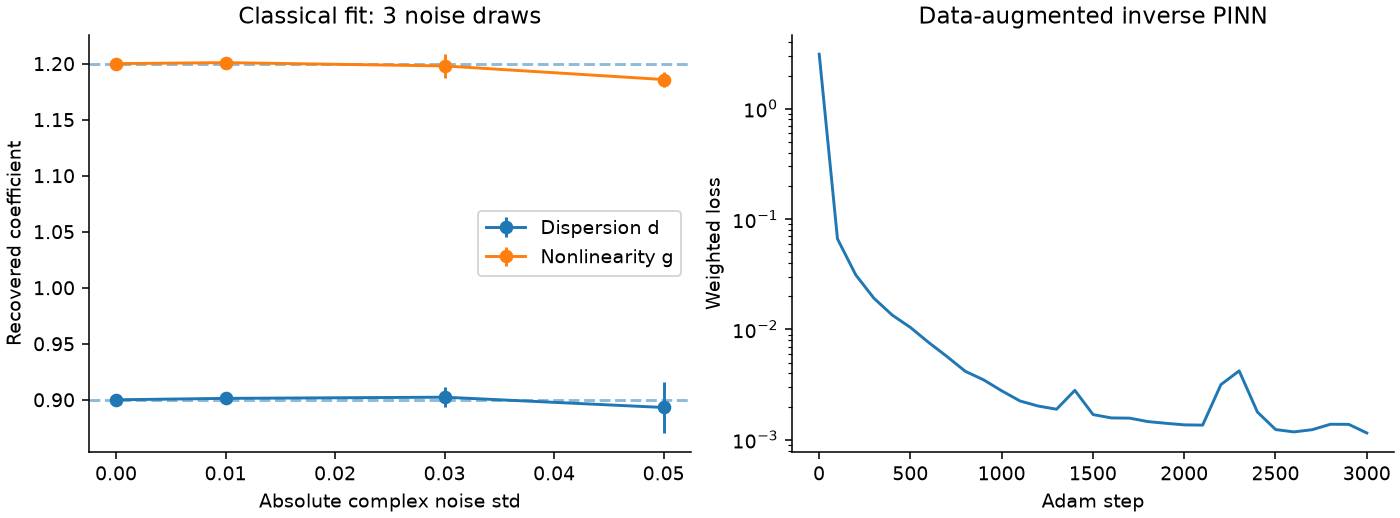

In [3]:
display(Image(filename=str(PROJECT / "results/inference.png")))

## Interpret and extend

Why generate with finer propagation steps than fitting? What changes if the detector measures only intensity? Discuss local conditioning versus global identifiability.

See `../report/technical_report.md` and the project README for the full experiment and limitations. Record your own changed settings and conclusions in a separate run.